In [2]:
import os
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={num_cores}"

# Visualize Model Output

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
-1.7266046493076295 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  1.7266046493076326


/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:218: RuntimeWarning: invalid value encountered in log10
  np.log10(self._data),
/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:1445: RuntimeWarning: invalid value encountered in log10
  np.log10(model),
/Users/rbrady0110/micromamba/envs/tensorflow/lib/python3.12/site-packages/lenstronomy/Plots/model_band_plot.py:916: RuntimeWarning: invalid value encountered in log10
  source_scale = np.log10(source)


<Axes: >

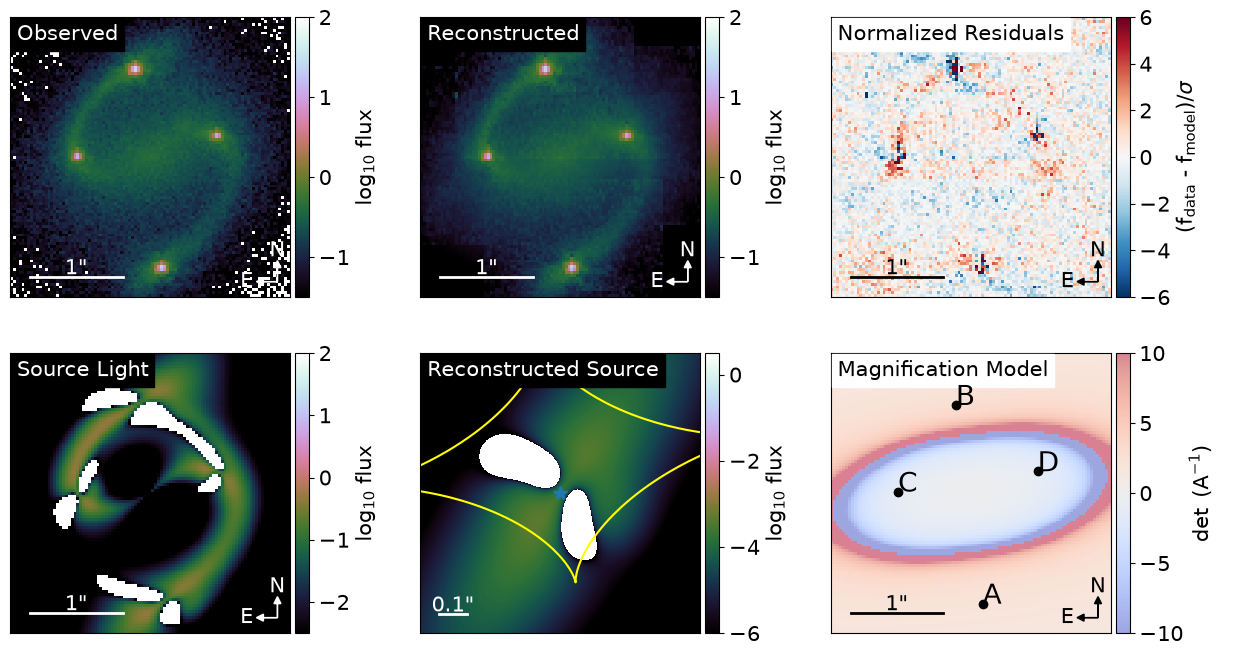

In [1]:
from dolphin.processor import Processor
from dolphin.analysis.output import Output
from dolphin.processor.config import ModelConfig
from lenstronomy.Plots.model_plot import ModelPlot
import matplotlib.pyplot as plt
import numpy as np

name='lensed_agn'
ID=f'jax'
io_dir=f"simulation"
output = Output(io_dir)

output.load_output(name, ID)

kwargs_result = output.kwargs_result
multi_band_list = output._multi_band_list_out
kwargs_data_joint = output.get_kwargs_data_joint(f"{name}")

config = ModelConfig(
            lens_name=name,
            io_directory=io_dir,
            settings=output.model_settings,
        )

mask = config.get_masks()
kwargs_model = config.get_kwargs_model()
constraints = config.get_kwargs_constraints()
likelihood = config.get_kwargs_likelihood()

modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result, image_likelihood_mask_list=mask)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

axes = ax.flatten()

modelPlot.data_plot(band_index=0, ax=axes[0], vmin=-1.5, vmax=2)
modelPlot.model_plot(ax=axes[1], band_index=0, vmin=-1.5, vmax=2)
modelPlot.normalized_residual_plot(ax=axes[2],vmin=-6,vmax=6,band_index=0, cmap='RdBu_r')

modelPlot.decomposition_plot(
            ax=axes[3], 
            kwargs_title={"text": "Source Light"}, 
            source_add=True, 
            unconvolved=True, 
            vmin=-2.5,
            vmax = 2.,
            band_index=0
                )
            
modelPlot.source_plot(
            ax=axes[4], kwargs_title={"text": "Reconstructed Source"}, delta_pix_source=0.001, num_pix=1000, vmin = -6., vmax = 0.5, band_index=0
            )    

modelPlot.magnification_plot(ax=axes[5], kwargs_title={"text": "Magnification Model"}, cmap='coolwarm', band_index=0)

# Compare lens model posteriors to truth

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


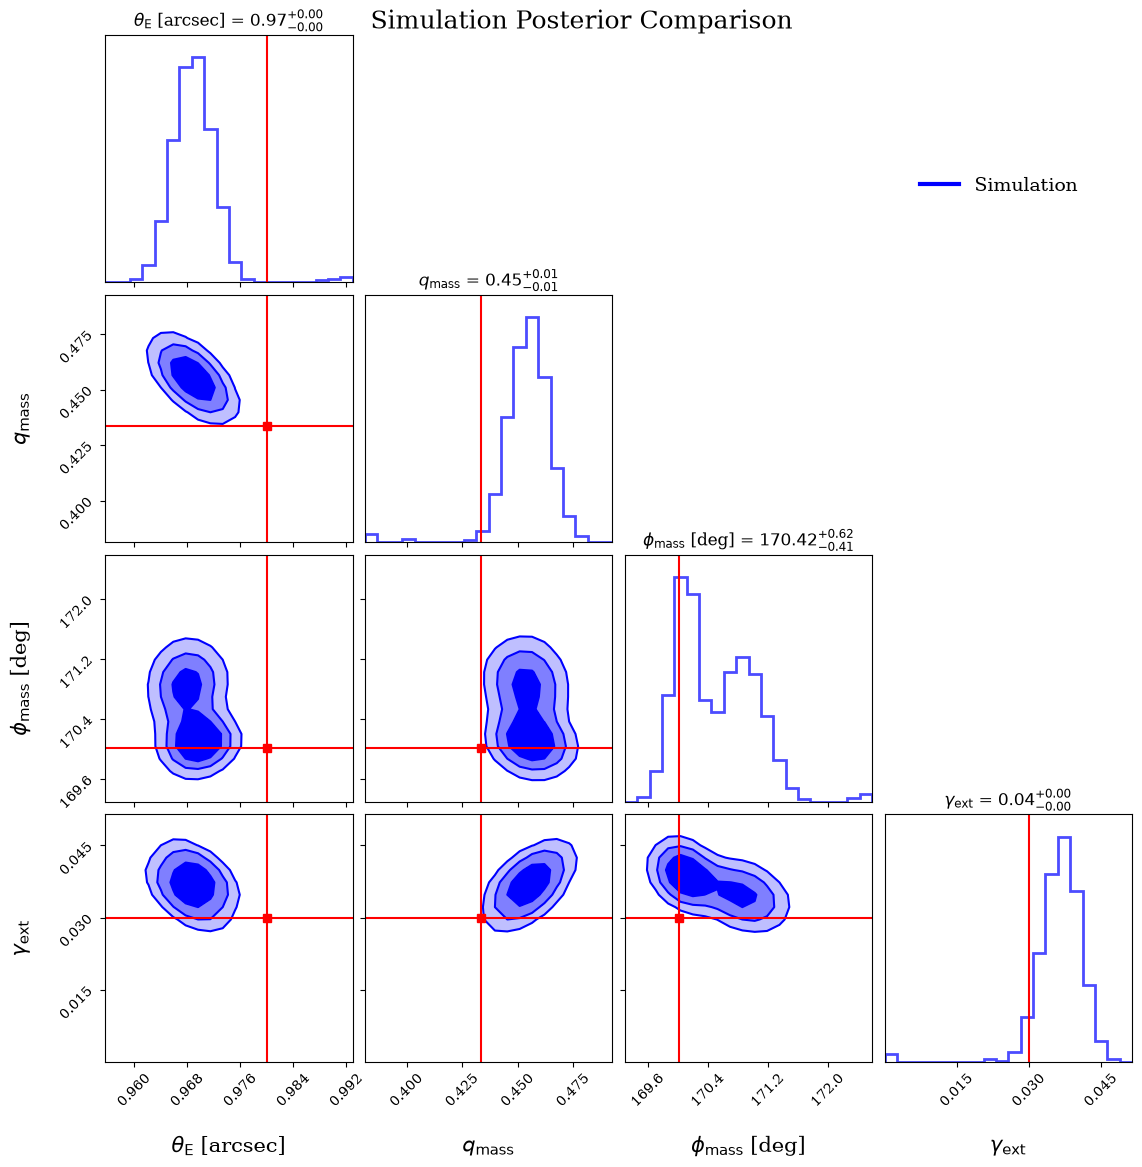

In [ ]:
import corner
import matplotlib as mpl
from lenstronomy.Util import param_util

mpl.rcParams["font.family"] = "serif"

def load_chain(output, param_names, name, model_id, walker_ratio, burn_in):
    """
    Extract specific parameters from `output`
    """

    chain = output.get_reshaped_emcee_chain(
        name, model_id, walker_ratio, burn_in=burn_in
    )

    num_params = output.num_params_sampled

    if len(param_names) == 0:
        parameter_list = np.arange(num_params)
    else:
        parameter_list = []
        for i in param_names:
            if i in output.params_sampled:
                parameter_list.append(output.params_sampled.index(i))
            else:
                raise ValueError(
                    f"Parameter '{i}' not found. Available parameters: {output.params_sampled}"
                )

    # Flatten walkers x steps for each requested parameter
    raw_samples = {}
    for i in parameter_list:
        param_name = output.params_sampled[i]
        raw_samples[param_name] = chain[:, :, i].flatten()

    return raw_samples

def convert_ellipticity_to_q_phi(e1_samples, e2_samples):
    
    # Convert e1, e2 to phi, q
    phi_mass, q_mass = param_util.ellipticity2phi_q(e1_samples, e2_samples)
    phi_mass = np.degrees(phi_mass) % 180
    
    return phi_mass, q_mass

param_names = [
    "theta_E_lens0",
    "e1_lens0",
    "e2_lens0",
    "gamma_ext_lens1",
]

# Load chains
name = "lensed_agn"
burn_in = 0

output = Output("simulation")
output.load_output("lensed_agn", "jax")
data_dict = load_chain(output, param_names, "lensed_agn",
                          "jax", 10, burn_in)
phi_mass, q_mass = convert_ellipticity_to_q_phi(data_dict["e1_lens0"], data_dict["e2_lens0"])
data_starred = np.column_stack([
    data_dict["theta_E_lens0"],
    q_mass,
    phi_mass,
    data_dict["gamma_ext_lens1"],
])

# Labels
labels = [
    r"$\theta_{\rm E}$ [arcsec]",
    r"$q_{\rm mass}$",
    r"$\phi_{\rm mass}$ [deg]",
    r"$\gamma_{\rm ext}$",
]


true_theta_E = .98
true_e1      = 0.371517
true_e2      = -0.13498
true_gamma_ext = 0.03

# Convert the truths the same way as the samples
true_phi_mass, true_q_mass = convert_ellipticity_to_q_phi(
    np.array([true_e1]), np.array([true_e2])
)

truths = [
    true_theta_E,
    true_q_mass[0],
    true_phi_mass[0],
    true_gamma_ext,
]

bins=20
fig = corner.corner(
    data_starred,
    labels=labels,
    truths=truths,
    truth_color="red",
    color="blue",
    levels=(0.393, 0.675, 0.865),
    smooth=1.0,
    fill_contours=True,
    plot_datapoints=False,
    show_titles=True,
    hist_kwargs={
        "linewidth": 2,
        "density": True,
        "alpha": 0.7,
    },
    contour_kwargs={
        "linewidths": 1.5,
    },
    label_kwargs={
        "fontsize": 15,
    },
    title_kwargs={
        "fontsize": 12,
    },
)

handles = [
    plt.Line2D(
        [],
        [],
        color="blue",
        lw=3,
        label="Simulation",
    ),
]

for ax in fig.get_axes():
    ax.tick_params(labelsize=10)


fig.axes[0].legend(
    handles=handles,
    fontsize=14,
    frameon=False,
    bbox_to_anchor=(4.0, 0.5),
)


plt.suptitle(
    "Simulation Posterior Comparison",
    fontsize=18,
)

fig.set_size_inches(
    12,
    12,
)


#plt.savefig("posterior.png")
plt.show()